In [1]:
from fluids.navier import pressure_poisson_jacobi, solve_NS
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Nx, Ny = 101, 101
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy

Lx = x[-1]
Ly = y[-1]

X, Y = np.meshgrid(x, y, indexing="ij")

p = np.zeros_like(X)

p_exact = (np.cos(np.pi * X / Lx) * np.cos(np.pi * Y / Ly))

f = -((np.pi / Lx) ** 2 + (np.pi / Ly) ** 2) * p_exact

In [3]:
new_p = pressure_poisson_jacobi(p, dx, dy, f, logs=True)

PPE solve iterations = 7822


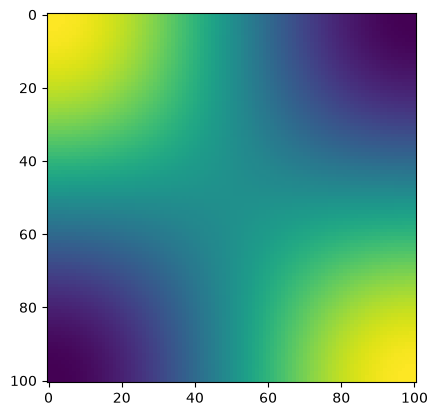

In [4]:
plt.imshow(new_p)

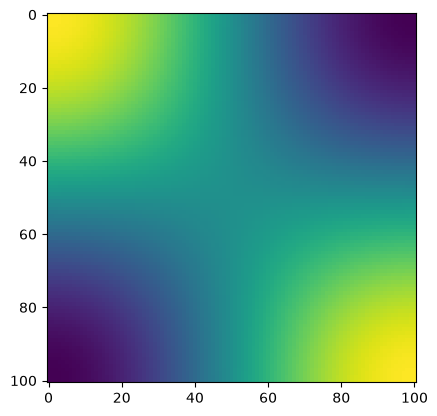

In [5]:
plt.imshow(p_exact)


Time = 0.00100000
PPE solve iterations = 10174
velocity residual = 1.3217132101537539

Time = 0.00200000
PPE solve iterations = 16250
velocity residual = 0.4289522906458565

Time = 0.00300000
PPE solve iterations = 9791
velocity residual = 0.24093922368073808

Time = 0.00400000
PPE solve iterations = 1785
velocity residual = 0.1615953662770112

Time = 0.00500000
PPE solve iterations = 1986
norm(u) = 0.64563121, norm(v) = 0.30950948
Courant number: 0.00598543
velocity residual = 0.11826238701260497

Time = 0.00600000
PPE solve iterations = 3104
velocity residual = 0.09118372700845649

Time = 0.00700000
PPE solve iterations = 2569
velocity residual = 0.07284901360244088

Time = 0.00800000
PPE solve iterations = 2263
velocity residual = 0.05978175527574793

Time = 0.00900000
PPE solve iterations = 2323
velocity residual = 0.050144834190262264

Time = 0.01000000
PPE solve iterations = 2474
norm(u) = 0.57577988, norm(v) = 0.33246839
Courant number: 0.00518059
velocity residual = 0.04286944

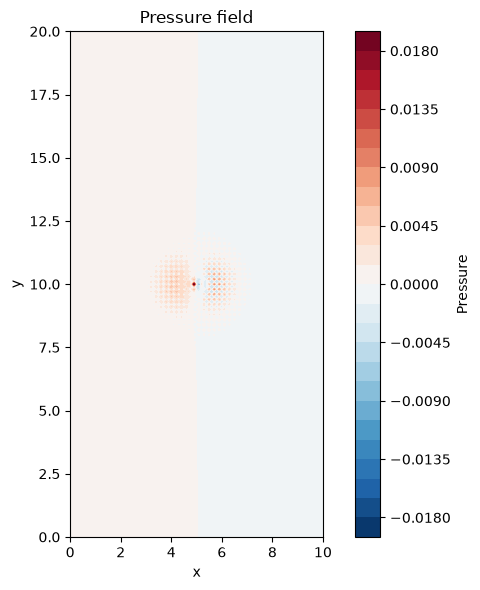

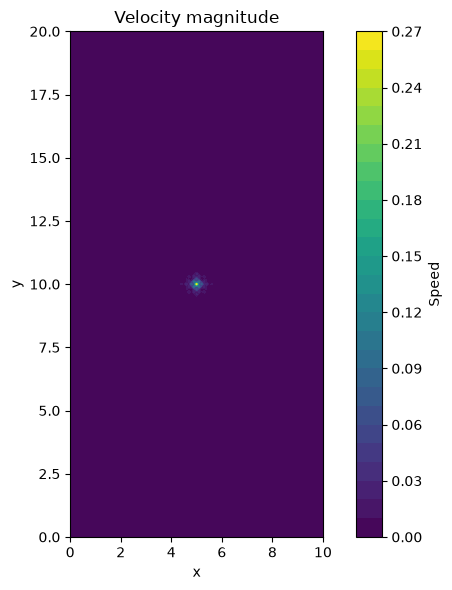

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
Nx, Ny = 101, 201
dx, dy = 0.1, 0.1

x = np.arange(Nx) * dx
y = np.arange(Ny) * dy
X, Y = np.meshgrid(x, y, indexing="ij")

# Fluid properties
rho = 1.0
nu = 0.01
dt = 0.001
t_end = 0.1

# Initialize fields
u = np.zeros((Nx, Ny))
v = np.zeros((Nx, Ny))
p = np.zeros((Nx, Ny))

# Localized velocity disturbance at the centre
i, j = Nx // 2, Ny // 2
u[i, j] = 1.0

# Run the solver
u, v, p = solve_NS(u, v, p, rho, nu, dt, t_end, dx, dy, logs=True)

# Plot pressure
fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, p, levels=30, cmap="RdBu_r")
fig.colorbar(contour, ax=ax, label="Pressure")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Pressure field")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Plot velocity magnitude
speed = np.sqrt(u**2 + v**2)

fig, ax = plt.subplots(figsize=(7, 6))
contour = ax.contourf(X, Y, speed, levels=30, cmap="viridis")
fig.colorbar(contour, ax=ax, label="Speed")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Velocity magnitude")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

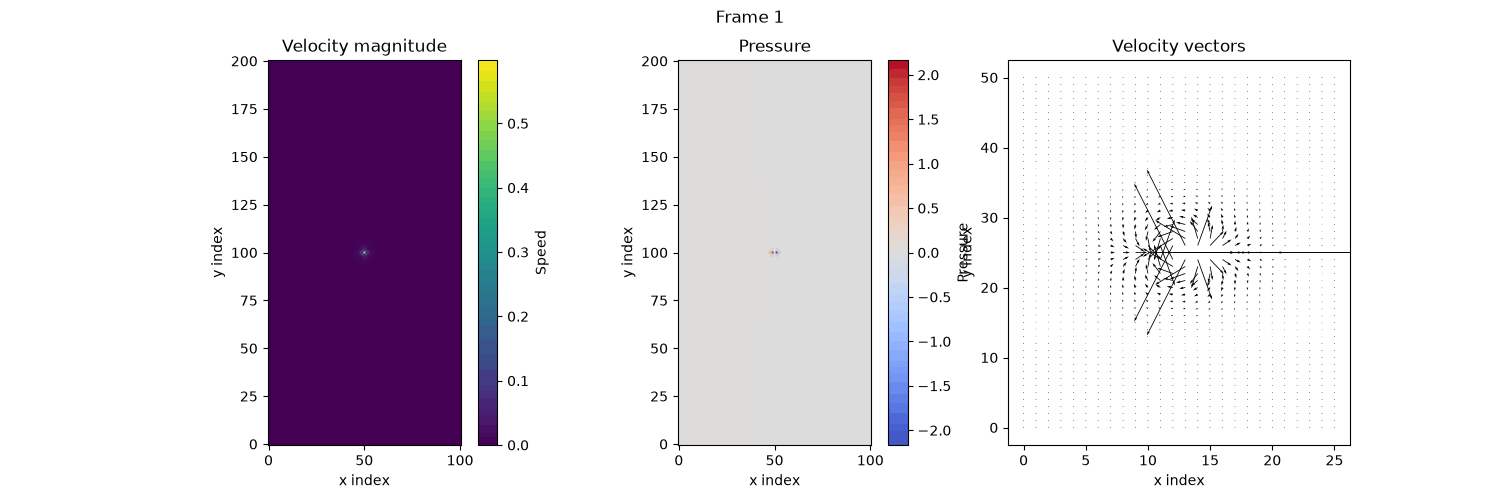

In [12]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(1, 3, figsize=(15, 5))

s = snapshots[0]
speed = np.hypot(s["u"], s["v"])
stride = 4

im1 = ax[0].imshow(speed.T, origin="lower", animated=True)
ax[0].set_title("Velocity magnitude")
fig.colorbar(im1, ax=ax[0], label="Speed")

im2 = ax[1].imshow(s["p"].T, origin="lower", cmap="coolwarm", animated=True)
ax[1].set_title("Pressure")
fig.colorbar(im2, ax=ax[1], label="Pressure")

q = ax[2].quiver(
    s["u"][::stride, ::stride].T,
    s["v"][::stride, ::stride].T,
)
ax[2].set_title("Velocity vectors")

title = fig.suptitle("")

# Consistent colour scales across frames
speed_max = max(np.hypot(s["u"], s["v"]).max() for s in snapshots)
p_min = min(s["p"].min() for s in snapshots)
p_max = max(s["p"].max() for s in snapshots)

im1.set_clim(0, max(speed_max, 1e-12))
im2.set_clim(p_min, p_max if p_max > p_min else p_min + 1e-12)

for a in ax:
    a.set_xlabel("x index")
    a.set_ylabel("y index")

def update(i):
    s = snapshots[i]
    speed = np.hypot(s["u"], s["v"])

    im1.set_data(speed.T)
    im2.set_data(s["p"].T)

    q.set_UVC(
        s["u"][::stride, ::stride].T,
        s["v"][::stride, ::stride].T,
    )

    t = s["t"]
    title.set_text(
        f"Navier–Stokes solution | t = {t:.4f}"
        if t is not None else f"Frame {i + 1}"
    )

    return im1, im2, q, title

ani = FuncAnimation(
    fig,
    update,
    frames=len(snapshots),
    interval=100,
    blit=False,
)

gif_path = Path("./output/navier_stokes.gif")
ani.save(gif_path, writer=PillowWriter(fps=10))
plt.close(fig)

display(Image(filename=str(gif_path)))